In [1]:

# Customer Churn Prediction
# Internship Project

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

print("\nAll libraries imported successfully!")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas Version: 2.2.3
NumPy Version: 2.4.6

All libraries imported successfully!


In [2]:

import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()



Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

# Step 3: Understanding the Dataset

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [4]:
# Convert TotalCharges safely
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Fill missing values with median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Check data types
print("\nData types:")
print(df.dtypes)

print("\nDataset shape:", df.shape)

print("\nData cleaning completed successfully!")

Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object

Customer Churn Count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


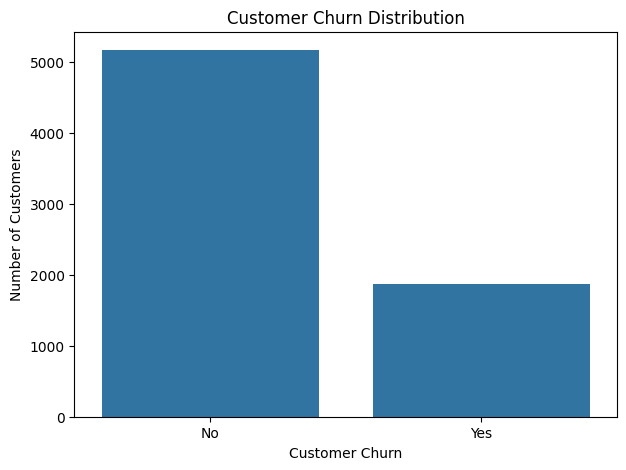

In [5]:
# Customer Churn Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Count churn customers
print("Customer Churn Count:")
print(df["Churn"].value_counts())

# Calculate percentage
print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

# Plot graph
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

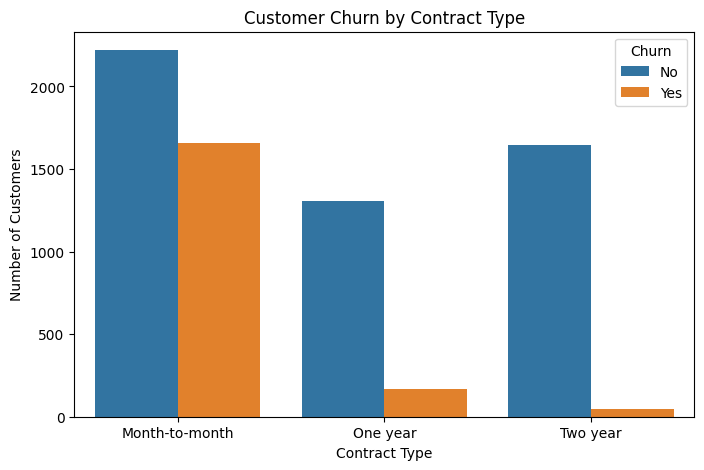

In [6]:
# Analyse churn based on contract type

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

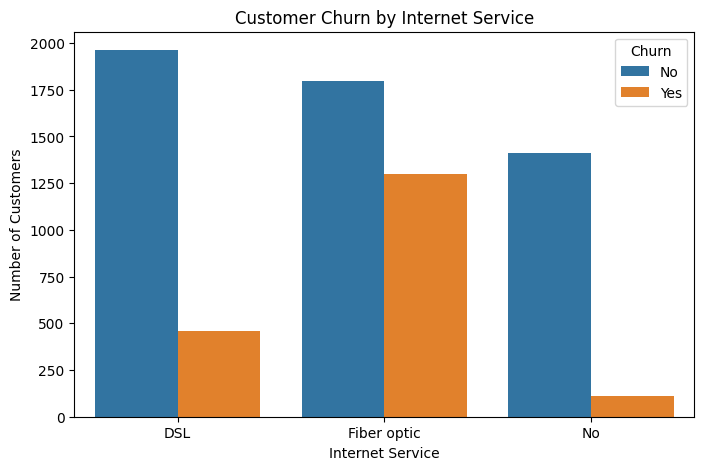

In [7]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

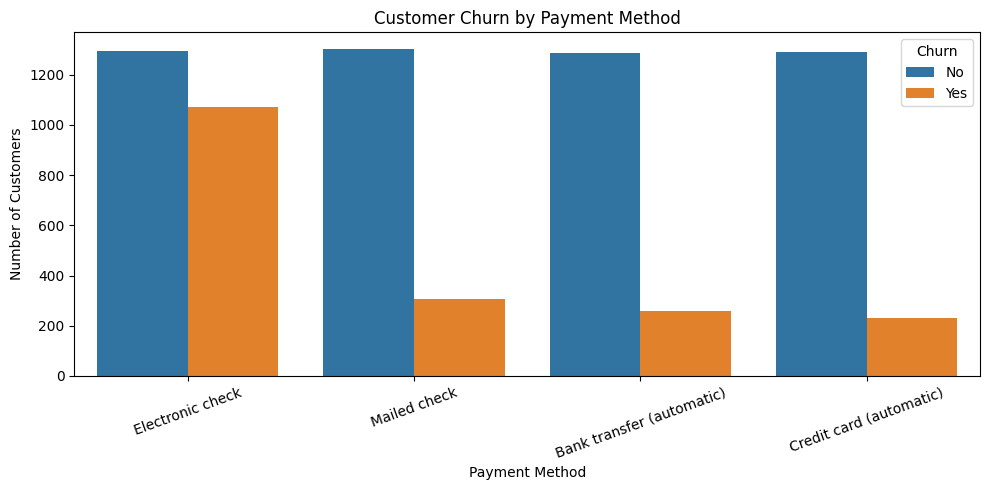

In [8]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [9]:
# Remove unnecessary customer ID column

df = df.drop('customerID', axis=1)

print("Customer ID removed successfully!")
print("Dataset shape:", df.shape)

Customer ID removed successfully!
Dataset shape: (7043, 20)


In [10]:
# Convert categorical columns into numerical values

df = pd.get_dummies(df, drop_first=True)

print("Categorical data converted successfully!")
print("New dataset shape:", df.shape)

df.head()

Categorical data converted successfully!
New dataset shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,True,False,True,False,False
1,0,34,56.95,1889.5,True,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,False
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,True,False,True,False,True


In [11]:
# Separate features and target

X = df.drop('Churn_Yes', axis=1)
y = df['Churn_Yes']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 30)
Target shape: (7043,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 30)
Testing data: (1409, 30)


In [13]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [14]:

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 78.63733144073811 %


In [15]:

from sklearn.metrics import classification_report

print("Random Forest Baseline Classification Report:")
print(classification_report(y_test, y_pred))


Random Forest Baseline Classification Report:
              precision    recall  f1-score   support

       False       0.83      0.89      0.86      1035
        True       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409



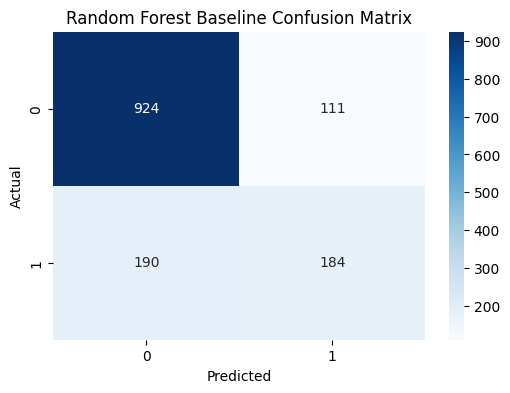

In [16]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Random Forest Baseline Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [17]:

from sklearn.metrics import classification_report

print("Random Forest Baseline Classification Report")
print(classification_report(y_test, y_pred))


Random Forest Baseline Classification Report
              precision    recall  f1-score   support

       False       0.83      0.89      0.86      1035
        True       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409



In [18]:
import joblib

joblib.dump(model, 'random_forest_baseline.pkl')

print("Model saved successfully!")

Model saved successfully!


In [19]:
print("PROJECT CONCLUSION")
print("Customer Churn Prediction using Machine Learning")
print("Selected Model: Logistic Regression")
print("Test Accuracy: 80.7%")
print("Test ROC-AUC: 0.842")
print("Five-fold Cross-validation ROC-AUC: 0.846")
print("Logistic Regression performed better than Random Forest")
print("on the reported comparison metrics.")
print("Churn-class recall is 56.7%, so some churn customers")
print("are still missed. Further improvement is recommended.")


PROJECT CONCLUSION
Customer Churn Prediction using Machine Learning
Selected Model: Logistic Regression
Test Accuracy: 80.7%
Test ROC-AUC: 0.842
Five-fold Cross-validation ROC-AUC: 0.846
Logistic Regression performed better than Random Forest
on the reported comparison metrics.
Churn-class recall is 56.7%, so some churn customers
are still missed. Further improvement is recommended.


In [20]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Define two classification algorithms
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# 5-Fold Cross Validation
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

results = []

for name, estimator in models.items():

    # Cross-validation
    cv_scores = cross_val_score(
        estimator, X_train, y_train,
        cv=cv, scoring="roc_auc"
    )

    # Train model
    estimator.fit(X_train, y_train)

    # Predictions
    y_pred = estimator.predict(X_test)
    positive_index = list(estimator.classes_).index(True)
    y_prob = estimator.predict_proba(X_test)[:, positive_index]

    # Evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=True),
        "Recall": recall_score(y_test, y_pred, pos_label=True),
        "F1 Score": f1_score(y_test, y_pred, pos_label=True),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "CV ROC-AUC": cv_scores.mean()
    })

# Display comparison
comparison = pd.DataFrame(results)
print("MODEL COMPARISON RESULTS")
display(comparison.round(3))


MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV ROC-AUC
0,Logistic Regression,0.807,0.658,0.567,0.609,0.842,0.846
1,Random Forest,0.786,0.624,0.492,0.550,0.825,0.824


## Final Model Selection and Evaluation

The initial Random Forest model is treated as a baseline. The comparison in the next section evaluates Logistic Regression and Random Forest using accuracy, precision, recall, F1-score, ROC-AUC and 5-fold cross-validation ROC-AUC. Logistic Regression is selected because it achieved the higher value for each reported metric. The following cell reports the selected model's final test-set classification metrics.

FINAL MODEL: LOGISTIC REGRESSION
              precision    recall  f1-score   support

       False       0.85      0.89      0.87      1035
        True       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



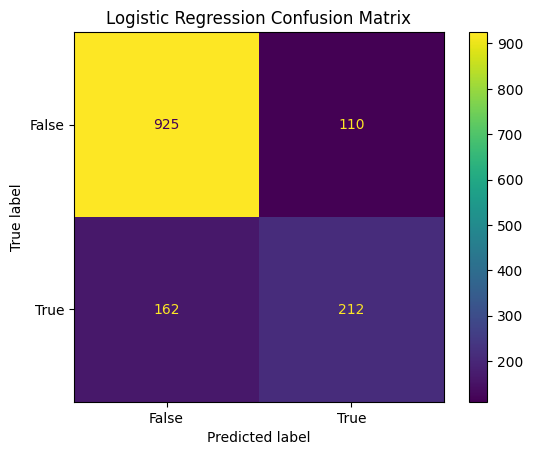

In [21]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Select Logistic Regression
best_model = models["Logistic Regression"]

# Predictions
y_pred_best = best_model.predict(X_test)

# Classification report
print("FINAL MODEL: LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_best))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [22]:
# Save the selected final model (Logistic Regression pipeline)
import joblib

joblib.dump(best_model, 'customer_churn_model.pkl')
print('Selected Logistic Regression model saved successfully!')

Selected Logistic Regression model saved successfully!
